# BERT-base fine tuning for paraphrase identification

## BERT-base (bert-base-uncased, 110M parameters), fine-tuned for 3 epochs with learning rate 2e-5, batch size 32, weight decay 0.01, max length 128, 5 seeds

In [5]:
import os, re, json
import numpy as np
import pandas as pd
from transformers import AutoTokenizer
import glob, shutil, json, subprocess, torch

from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import roc_auc_score, confusion_matrix
from scipy.special import softmax
import matplotlib.pyplot as plt, seaborn as sns

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HOME"] = "/scratch/bhandari.ru/hf_cache"

/home/bhandari.ru/.local/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.0.post1)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(
2026-11-02 18:51:50.696480: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793663511.030907  487222 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793663511.107030  487222 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793663511.945032  487222 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793663511.945074  4872

### GPU Check

In [6]:
# GPU details
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    pr = torch.cuda.get_device_properties(0)
    print("GPU:", pr.name)
    print(f"Memory: {pr.total_memory/1e9:.0f} GB")
    print("Compute capability:", f"{pr.major}.{pr.minor}")
    print("GPUs visible:", torch.cuda.device_count())

print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

CUDA available: True
GPU: Tesla V100-SXM2-32GB
Memory: 34 GB
Compute capability: 7.0
GPUs visible: 1
Mon Nov  2 18:51:58 2026       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 545.23.08              Driver Version: 545.23.08    CUDA Version: 12.3     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla V100-SXM2-32GB           On  | 00000000:18:00.0 Off |                    0 |
| N/A   45C    P0              45W / 300W |      3MiB / 32768MiB |      0%      Default |
|                                         |              

### Setting up the paths

In [25]:
SEEDS = [42, 43, 44, 45, 46]        
SPLITS = "/home/bhandari.ru/NLP project/splits"  
OUT = "/scratch/bhandari.ru/paraphrase/out_team"
RESULTS = "/home/bhandari.ru/NLP project/bert_base_results"

for p in (OUT, RESULTS):
    os.makedirs(p, exist_ok=True)

print(sorted(os.listdir(SPLITS))) 

['.ipynb_checkpoints', 'mrpc_dev.csv', 'mrpc_test.csv', 'mrpc_train.csv', 'paws_dev.csv', 'paws_test.csv', 'paws_train.csv', 'qqp_dev.csv', 'qqp_test.csv', 'qqp_train.csv']


### Load the cleaned data splits

In [12]:
data = {}
for ds in ["mrpc", "qqp", "paws"]:
    data[ds] = {}
    for split in ["train", "dev", "test"]:
        df = pd.read_csv(f"{SPLITS}/{ds}_{split}.csv", keep_default_na=False)
        df["sentence1"] = df["sentence1"].astype(str)
        df["sentence2"] = df["sentence2"].astype(str)
        data[ds][split] = df

In [13]:
expected = {
    "mrpc": {"train": 3301,  "dev": 367,  "test": 408},
    "qqp":  {"train": 36000, "dev": 4000, "test": 5000},
    "paws": {"train": 49259, "dev": 7983, "test": 8000},
}
for ds in data:
    for split, df in data[ds].items():
        n, pct = len(df), df["label"].mean() * 100
        ok = "OK" if n == expected[ds][split] else "MISMATCH"
        print(f"{ds}_{split}: {n} pairs, {pct:.1f}% paraphrase  [{ok}]")
    print("  majority-class test acc:",
          round(max(data[ds]["test"].label.mean(), 1 - data[ds]["test"].label.mean()), 3))

mrpc_train: 3301 pairs, 67.8% paraphrase  [OK]
mrpc_dev: 367 pairs, 64.6% paraphrase  [OK]
mrpc_test: 408 pairs, 68.4% paraphrase  [OK]
  majority-class test acc: 0.684
qqp_train: 36000 pairs, 36.7% paraphrase  [OK]
qqp_dev: 4000 pairs, 35.8% paraphrase  [OK]
qqp_test: 5000 pairs, 36.7% paraphrase  [OK]
  majority-class test acc: 0.633
paws_train: 49259 pairs, 44.1% paraphrase  [OK]
paws_dev: 7983 pairs, 44.2% paraphrase  [OK]
paws_test: 8000 pairs, 44.2% paraphrase  [OK]
  majority-class test acc: 0.558


### Data Leakage Check (Train/Dev/Test Overlap)

In [14]:
def key(a, b):
    return tuple(sorted([a.lower().strip(), b.lower().strip()]))

def keys(df):
    return [key(a, b) for a, b in zip(df.sentence1, df.sentence2)]

for ds in data:
    tr, dv, te = (set(keys(data[ds][s])) for s in ["train", "dev", "test"])
    print(f"{ds}: train∩test={len(tr & te)}, dev∩test={len(dv & te)}, train∩dev={len(tr & dv)}")

mrpc: train∩test=0, dev∩test=0, train∩dev=0
qqp: train∩test=0, dev∩test=0, train∩dev=0
paws: train∩test=0, dev∩test=0, train∩dev=0


### Data Quality check

#### PAWS Error Analysis by Word Overlap

In [16]:

te = data["paws"]["test"].copy()
bag = lambda s: tuple(sorted(re.findall(r"\w+", s.lower())))
jac = lambda a, b: len(set(re.findall(r"\w+", a.lower())) & set(re.findall(r"\w+", b.lower()))) / \
                   max(1, len(set(re.findall(r"\w+", a.lower())) | set(re.findall(r"\w+", b.lower()))))

te["same_bag"] = [bag(a) == bag(b) for a, b in zip(te.sentence1, te.sentence2)]
te["jac"] = [jac(a, b) for a, b in zip(te.sentence1, te.sentence2)]
te["bucket"] = pd.cut(te.jac, [0, .7, .8, .9, .99, 1.0], include_lowest=True)

# fraction of seeds that got each test row right
te["bert_correct"] = np.mean([np.load(f"{OUT}/bert_paws_s{s}_test_preds.npy") == te.label.values
                              for s in SEEDS], axis=0)

print("Same words, different order (bag-of-words can't separate these):")
print(te.groupby("same_bag").agg(n=("label", "size"), pct_para=("label", "mean"),
                                 bert_acc=("bert_correct", "mean")).round(3), "\n")
print(te.groupby("bucket", observed=True).agg(n=("label", "size"), pct_para=("label", "mean"),
                                              bert_acc=("bert_correct", "mean")).round(3), "\n")

# dev vs test, per seed
for s in SEEDS:
    r = json.load(open(f"{OUT}/bert_paws_s{s}_metrics.json"))
    print(s, "best dev F1:", round(max(c["dev_f1"] for c in r["dev_curve"]), 3),
          "| test F1:", round(r["test_f1"], 3))

Same words, different order (bag-of-words can't separate these):
             n  pct_para  bert_acc
same_bag                          
False     7147     0.459     0.906
True       853     0.298     0.928 

                  n  pct_para  bert_acc
bucket                                 
(-0.001, 0.7]    26     0.077     0.915
(0.7, 0.8]      545     0.319     0.881
(0.8, 0.9]     4020     0.470     0.898
(0.9, 0.99]    1965     0.470     0.918
(0.99, 1.0]    1444     0.377     0.933 

42 best dev F1: 0.914 | test F1: 0.901
43 best dev F1: 0.91 | test F1: 0.899
44 best dev F1: 0.917 | test F1: 0.902
45 best dev F1: 0.908 | test F1: 0.897
46 best dev F1: 0.911 | test F1: 0.902


In [15]:
rows = []
for ds in data:
    for split, df in data[ds].items():
        k = keys(df)
        d = df.assign(key=k)
        rows.append({
            "split": f"{ds}_{split}",
            "rows": len(df),
            "dup_pairs": int(d.duplicated("key").sum()),
            "conflicts": int((d.groupby("key").label.nunique() > 1).sum()),
            "empty": int(((df.sentence1.str.strip() == "") | (df.sentence2.str.strip() == "")).sum()),
            "bad_labels": int((~df.label.isin([0, 1])).sum()),
            "identical_AB": int((df.sentence1.str.lower().str.strip() == df.sentence2.str.lower().str.strip()).sum()),
        })
pd.DataFrame(rows)

,split,rows,dup_pairs,conflicts,empty,bad_labels,identical_AB
0,mrpc_train,3301,0,0,0,0,0
1,mrpc_dev,367,0,0,0,0,0
2,mrpc_test,408,0,0,0,0,0
3,qqp_train,36000,0,0,0,0,4
4,qqp_dev,4000,0,0,0,0,1
5,qqp_test,5000,0,0,0,0,0
6,paws_train,49259,0,0,0,0,58
7,paws_dev,7983,0,0,0,0,8
8,paws_test,8000,28,7,0,0,14


### Sentence-Level Leakage Check

In [16]:
def sents(df):
    return set(df.sentence1.str.lower().str.strip()) | set(df.sentence2.str.lower().str.strip())

for ds in data:
    tr_s = sents(data[ds]["train"])
    for split in ["dev", "test"]:
        df = data[ds][split]
        a = df.sentence1.str.lower().str.strip().isin(tr_s)
        b = df.sentence2.str.lower().str.strip().isin(tr_s)
        print(f"{ds}_{split}: one+ sentence in train = {(a|b).sum()}/{len(df)} "
              f"({(a|b).mean()*100:.1f}%), both = {(a&b).sum()}")

mrpc_dev: one+ sentence in train = 50/367 (13.6%), both = 2
mrpc_test: one+ sentence in train = 37/408 (9.1%), both = 2
qqp_dev: one+ sentence in train = 898/4000 (22.4%), both = 243
qqp_test: one+ sentence in train = 1171/5000 (23.4%), both = 350
paws_dev: one+ sentence in train = 0/7983 (0.0%), both = 0
paws_test: one+ sentence in train = 0/8000 (0.0%), both = 0


### Loading the BERT tokenizer and Token Length Check

In [17]:
MODEL_NAME = "bert-base-uncased" 
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

for ds in data:
    df = data[ds]["train"]
    lens = np.array([len(x) for x in tok(df.sentence1.tolist(), df.sentence2.tolist())["input_ids"]])
    print(f"{ds}: median={np.median(lens):.0f}, p95={np.percentile(lens,95):.0f}, "
          f"p99={np.percentile(lens,99):.0f}, max={lens.max()}, over128={(lens>128).mean()*100:.2f}%")

/home/bhandari.ru/.local/lib/python3.10/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.0.post1)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


mrpc: median=54, p95=74, p99=83, max=103, over128=0.00%
qqp: median=27, p95=55, p99=74, max=323, over128=0.03%
paws: median=52, p95=75, p99=85, max=143, over128=0.01%


### Leak Guard and Tokenization Helpers

In [18]:
# Leak guard: runs before any training
for ds in data:
    tr, dv, te = (set(keys(data[ds][s])) for s in ["train", "dev", "test"])
    assert not (tr & te) and not (tr & dv) and not (dv & te), f"LEAK in {ds}"
print("Leak guard passed")

_tok_cache = {}
def get_tok(model_name):
    if model_name not in _tok_cache:
        _tok_cache[model_name] = AutoTokenizer.from_pretrained(model_name)
    return _tok_cache[model_name]

def build(ds, model_name, max_len=128):
    tok = get_tok(model_name)
    out = {}
    for split in ["train", "dev", "test"]:
        df = data[ds][split][["sentence1", "sentence2", "label"]].reset_index(drop=True)
        d = Dataset.from_pandas(df, preserve_index=False)
        d = d.map(lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=max_len),
                  batched=True, remove_columns=["sentence1", "sentence2"])
        out[split] = d
    return out

2026-11-02 00:50:11.178556: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793598611.540403 2032789 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793598611.633534 2032789 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793598612.668969 2032789 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793598612.669015 2032789 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793598612.669018 2032789 computation_placer.cc:177] computation placer alr

Leak guard passed


### Model Training and Evaluation Function

In [19]:
def metrics(p):
    preds = np.argmax(p.predictions, axis=-1)
    y = p.label_ids
    return {"accuracy": accuracy_score(y, preds),
            "precision": precision_score(y, preds, zero_division=0),
            "recall": recall_score(y, preds, zero_division=0),
            "f1": f1_score(y, preds)}

def run(ds, seed=42, model_name="bert-base-uncased", epochs=3, save_model=False, force=False, suffix=""):
    short = model_name.split("/")[-1].split("-")[0]        
    tag = f"{short}_{ds}_s{seed}{suffix}"    
    result_path = f"{OUT}/{tag}_metrics.json"
    if os.path.exists(result_path) and not force:
        print("Already done:", tag); return json.load(open(result_path))

    set_seed(seed)
    tok = get_tok(model_name)
    d = build(ds, model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

    args = TrainingArguments(
        output_dir=f"{OUT}/{tag}", learning_rate=2e-5,
        per_device_train_batch_size=32, per_device_eval_batch_size=64,
        num_train_epochs=epochs, weight_decay=0.01, seed=seed,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        save_only_model=True, load_best_model_at_end=True, metric_for_best_model="f1",
        logging_steps=50, fp16=torch.cuda.is_available(), report_to="none")

    trainer = Trainer(model=model, args=args, train_dataset=d["train"], eval_dataset=d["dev"],
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()

    dev_curve = [{"epoch": h["epoch"], "dev_f1": h["eval_f1"], "dev_loss": h["eval_loss"]}
                 for h in trainer.state.log_history if "eval_f1" in h]

    out = trainer.predict(d["test"])                      
    preds = np.argmax(out.predictions, -1)
    y = np.array(data[ds]["test"]["label"])
    assert len(preds) == len(y)

    np.save(f"{OUT}/{tag}_test_preds.npy", preds)
    np.save(f"{OUT}/{tag}_test_logits.npy", out.predictions)

    res = {"tag": tag, "model": model_name, "dataset": ds, "seed": seed,
           "n_train": len(d["train"]), "n_test": len(y),
           "test_accuracy": float(accuracy_score(y, preds)),
           "test_precision": float(precision_score(y, preds, zero_division=0)),
           "test_recall": float(recall_score(y, preds, zero_division=0)),
           "test_f1": float(f1_score(y, preds)),
           "majority_acc": float(max(y.mean(), 1 - y.mean())),
           "frac_pred_paraphrase": float(preds.mean()),
           "dev_curve": dev_curve}
    json.dump(res, open(result_path, "w"), indent=2)

    if save_model:
        trainer.save_model(f"{OUT}/{tag}/best")
    for ck in glob.glob(f"{OUT}/{tag}/checkpoint-*"):
        shutil.rmtree(ck, ignore_errors=True)

 
    for f in glob.glob(f"{OUT}/{tag}_*.npy") + [result_path]:
        shutil.copy(f, RESULTS)
    print(tag, {k: round(v, 4) for k, v in res.items() if k.startswith("test_")})
    return res

In [10]:
r = run("mrpc", seed=42) # Test training on mrpc for seed=42

Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.510900,0.513874,0.746594,0.748276,0.915612,0.823529
2,0.379400,0.427197,0.803815,0.836735,0.864979,0.850622
3,0.267900,0.442747,0.792916,0.818182,0.873418,0.844898


bert_mrpc_s42 {'test_accuracy': 0.8113, 'test_precision': 0.8322, 'test_recall': 0.9068, 'test_f1': 0.8679}


### Epoch Sensitivity Check (3 vs 5 epochs)

In [13]:
r5 = run("mrpc", seed=42, epochs=5, suffix="_ep5")
for c in r5["dev_curve"]:
    print(c)
print("3-epoch run test acc/F1:", round(r["test_accuracy"], 4), round(r["test_f1"], 4))
print("5-epoch run test acc/F1:", round(r5["test_accuracy"], 4), round(r5["test_f1"], 4))

Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.509300,0.497723,0.749319,0.756184,0.902954,0.823077
2,0.372500,0.409576,0.806540,0.854701,0.843882,0.849257
3,0.233900,0.469378,0.801090,0.803704,0.915612,0.856016
4,0.132400,0.514627,0.801090,0.812977,0.898734,0.853707
5,0.075600,0.570878,0.798365,0.805243,0.907173,0.853175


bert_mrpc_s42_ep5 {'test_accuracy': 0.8407, 'test_precision': 0.8408, 'test_recall': 0.9462, 'test_f1': 0.8904}
{'epoch': 1.0, 'dev_f1': 0.823076923076923, 'dev_loss': 0.49772346019744873}
{'epoch': 2.0, 'dev_f1': 0.8492569002123143, 'dev_loss': 0.40957608819007874}
{'epoch': 3.0, 'dev_f1': 0.8560157790927022, 'dev_loss': 0.4693783223628998}
{'epoch': 4.0, 'dev_f1': 0.8537074148296593, 'dev_loss': 0.5146265625953674}
{'epoch': 5.0, 'dev_f1': 0.8531746031746031, 'dev_loss': 0.5708775520324707}
3-epoch run test acc/F1: 0.8113 0.8679
5-epoch run test acc/F1: 0.8407 0.8904


### Training All Models (3 Datasets x 5 Seeds)

In [15]:
for ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        run(ds, seed=s, save_model=(ds == "qqp"))

Already done: bert_mrpc_s42


Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.545200,0.512160,0.749319,0.759857,0.894515,0.821705
2,0.392000,0.476566,0.768392,0.783582,0.886076,0.831683
3,0.277100,0.475103,0.776567,0.792453,0.886076,0.836653


... (75 outputs left out)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.286500,0.267605,0.898785,0.859296,0.921702,0.889406
2,0.198100,0.290541,0.913316,0.871882,0.942128,0.905645
3,0.107200,0.309911,0.917825,0.872694,0.952908,0.911039


bert_paws_s46 {'test_accuracy': 0.9101, 'test_precision': 0.8671, 'test_recall': 0.9409, 'test_f1': 0.9025}


### Backing up Results and Saving Models

In [21]:
shutil.copytree(RESULTS, RESULTS + "_backup", dirs_exist_ok=True)

for ds in ["mrpc", "paws"]:
    for s in SEEDS:
        run(ds, seed=s, save_model=True, suffix="_saved")

Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.510900,0.513874,0.746594,0.748276,0.915612,0.823529
2,0.379400,0.427197,0.803815,0.836735,0.864979,0.850622
3,0.267900,0.442747,0.792916,0.818182,0.873418,0.844898


bert_mrpc_s42_saved {'test_accuracy': 0.8113, 'test_precision': 0.8322, 'test_recall': 0.9068, 'test_f1': 0.8679}


... (50 outputs left out)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.286500,0.267605,0.898785,0.859296,0.921702,0.889406
2,0.198100,0.290541,0.913316,0.871882,0.942128,0.905645
3,0.107200,0.309911,0.917825,0.872694,0.952908,0.911039


bert_paws_s46_saved {'test_accuracy': 0.9101, 'test_precision': 0.8671, 'test_recall': 0.9409, 'test_f1': 0.9025}


### BERT Results Table

In [18]:
rows = []
for ds in ["mrpc", "qqp", "paws"]:
    rs = [json.load(open(f"{OUT}/bert_{ds}_s{s}_metrics.json")) for s in SEEDS]
    row = {"dataset": ds, "majority_acc": round(rs[0]["majority_acc"], 3)}
    for m in ["accuracy", "precision", "recall", "f1"]:
        v = np.array([x[f"test_{m}"] for x in rs])
        row[m] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(f"{RESULTS}/bert_summary.csv", index=False)
summary

,dataset,majority_acc,accuracy,precision,recall,f1
0,mrpc,0.684,0.805 ± 0.012,0.812 ± 0.022,0.931 ± 0.024,0.867 ± 0.005
1,qqp,0.633,0.855 ± 0.005,0.773 ± 0.014,0.857 ± 0.015,0.813 ± 0.005
2,paws,0.558,0.908 ± 0.003,0.864 ± 0.014,0.940 ± 0.015,0.900 ± 0.002


### Cross Datasets Testing

#### QQP -> PAWS, 5 Seeds

In [17]:
mn = "bert-base-uncased"
tok = get_tok(mn)
dp = build("paws", mn)
y = data["paws"]["test"]["label"].values

rows = []
for s in SEEDS:
    model = AutoModelForSequenceClassification.from_pretrained(f"{OUT}/bert_qqp_s{s}/best")
    tr = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                 args=TrainingArguments(output_dir=f"{OUT}/tmp", per_device_eval_batch_size=64,
                                        fp16=torch.cuda.is_available(), report_to="none"))
    out = tr.predict(dp["test"])
    p = np.argmax(out.predictions, -1)
    np.save(f"{OUT}/bert_qqp_on_paws_s{s}_test_preds.npy", p)
    np.save(f"{OUT}/bert_qqp_on_paws_s{s}_test_logits.npy", out.predictions)
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    rows.append({"seed": s, "acc": accuracy_score(y, p), "f1": f1_score(y, p),
                 "frac_pred_para": p.mean(), "recall": tp/(tp+fn), "specificity": tn/(tn+fp),
                 "TN": tn, "FP": fp, "FN": fn, "TP": tp})

cross = pd.DataFrame(rows).round(3)
display(cross)
print(cross[["acc", "f1", "frac_pred_para", "recall", "specificity"]].agg(["mean", "std"]).round(3))

for f in glob.glob(f"{OUT}/bert_qqp_on_paws_*.npy"):
    shutil.copy(f, RESULTS)

Map:   0%|          | 0/49259 [00:00<?, ? examples/s]

Map:   0%|          | 0/7983 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

,seed,acc,f1,frac_pred_para,recall,specificity,TN,FP,FN,TP
0,42,0.463,0.597,0.890,0.899,0.117,523,3941,356,3180
1,43,0.500,0.560,0.693,0.719,0.328,1462,3002,995,2541
2,44,0.486,0.573,0.763,0.781,0.252,1123,3341,774,2762
3,45,0.502,0.494,0.541,0.549,0.466,2078,2386,1595,1941
4,46,0.475,0.573,0.788,0.798,0.220,981,3483,715,2821


        acc     f1  frac_pred_para  recall  specificity
mean  0.485  0.559           0.735   0.749        0.277
std   0.017  0.039           0.129   0.129        0.130


### Full Transfer Matrix (Train on One Dataset, Test on All Three)

#### Every trained model is tested on every test set, with no retraining. That’s 3 train sets × 5 seeds × 3 test sets, 45 evaluations.

In [23]:
def model_dir(train_ds, s):
    return f"{OUT}/bert_{train_ds}_s{s}" + ("" if train_ds == "qqp" else "_saved") + "/best"

mn = "bert-base-uncased"
tok = get_tok(mn)
built = {ds: build(ds, mn) for ds in ["mrpc", "qqp", "paws"]}

rows = []
for train_ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        model = AutoModelForSequenceClassification.from_pretrained(model_dir(train_ds, s))
        tr = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                     args=TrainingArguments(output_dir=f"{OUT}/tmp", per_device_eval_batch_size=64,
                                            fp16=torch.cuda.is_available(), report_to="none"))
        for test_ds in ["mrpc", "qqp", "paws"]:
            out = tr.predict(built[test_ds]["test"])
            y = data[test_ds]["test"]["label"].values
            p = np.argmax(out.predictions, -1)
            prob = softmax(out.predictions, axis=-1)[:, 1]
            np.save(f"{OUT}/xfer_{train_ds}_on_{test_ds}_s{s}_preds.npy", p)
            np.save(f"{OUT}/xfer_{train_ds}_on_{test_ds}_s{s}_logits.npy", out.predictions)
            rows.append({"train": train_ds, "test": test_ds, "seed": s,
                         "acc": accuracy_score(y, p), "f1": f1_score(y, p),
                         "auc": roc_auc_score(y, prob), "frac_pred_para": p.mean(),
                         "majority_acc": max(y.mean(), 1 - y.mean())})
        del model, tr
        torch.cuda.empty_cache()

xfer = pd.DataFrame(rows)
xfer.to_csv(f"{RESULTS}/transfer_all_runs.csv", index=False)
for f in glob.glob(f"{OUT}/xfer_*.npy"):
    shutil.copy(f, RESULTS)

def ms(x): return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}"
for m in ["acc", "auc", "frac_pred_para"]:
    print(f"\n{m} (rows = trained on, cols = tested on)")
    display(xfer.pivot_table(index="train", columns="test", values=m, aggfunc=ms))
print("\nmajority accuracy per test set:")
print(xfer.groupby("test").majority_acc.first().round(3))

Map:   0%|          | 0/3301 [00:00<?, ? examples/s]

Map:   0%|          | 0/367 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/36000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

... (6 outputs left out)

test,mrpc,paws,qqp
train,,,
mrpc,0.849 ± 0.009,0.508 ± 0.008,0.736 ± 0.015
paws,0.713 ± 0.029,0.964 ± 0.002,0.719 ± 0.049
qqp,0.724 ± 0.015,0.534 ± 0.019,0.929 ± 0.002



frac_pred_para (rows = trained on, cols = tested on)


test,mrpc,paws,qqp
train,,,
mrpc,0.785 ± 0.041,0.973 ± 0.038,0.631 ± 0.118
paws,0.777 ± 0.067,0.481 ± 0.015,0.590 ± 0.083
qqp,0.590 ± 0.099,0.735 ± 0.130,0.407 ± 0.014



majority accuracy per test set:
test
mrpc    0.684
paws    0.558
qqp     0.633
Name: majority_acc, dtype: float64


### Testing all 3 models on handwriten, new test cases.

#### Loads one trained model per dataset (seed 44: MRPC, QQP, PAWS) and shows how each scores completly new hand written sentence pairs.

In [24]:
def load(train_ds, s=44):
    d = f"{OUT}/bert_{train_ds}_s{s}" + ("" if train_ds == "qqp" else "_saved") + "/best"
    m = AutoModelForSequenceClassification.from_pretrained(d).eval()
    return m.cuda() if torch.cuda.is_available() else m

models_demo = {ds: load(ds) for ds in ["mrpc", "qqp", "paws"]}
tok = get_tok("bert-base-uncased")

def predict(s1, s2):
    enc = tok(s1, s2, return_tensors="pt", truncation=True, max_length=128)
    enc = {k: v.to(next(iter(models_demo.values())).device) for k, v in enc.items()}
    row = {}
    for name, m in models_demo.items():
        with torch.no_grad():
            p = softmax(m(**enc).logits.cpu().numpy(), axis=-1)[0, 1]
        row[name + "_model"] = f"{p:.2f}"
    return row

pairs = [
    #(sentence1, sentence2, what we expect)
    ("The cat sat on the mat.", "A cat was sitting on the mat.", "paraphrase"),
    ("The dog chased the postman.", "The postman chased the dog.", "NOT (swapped roles)"),
    ("How do I learn Python quickly?", "What is the fastest way to learn Python?", "paraphrase"),
    ("She gave the book to him.", "He gave the book to her.", "NOT (swapped roles)"),
    ("The company reported record profits in 2025.", "The firm posted its highest ever earnings last year.", "paraphrase"),
    ("I love pizza.", "The stock market closed lower today.", "NOT (unrelated)"),
]

rows = []
for a, b, exp in pairs:
    rows.append({"s1": a, "s2": b, "expected": exp, **predict(a, b)})
pd.set_option("display.max_colwidth", 60)
pd.DataFrame(rows)

,s1,s2,expected,mrpc_model,qqp_model,paws_model
0,The cat sat on the mat.,A cat was sitting on the mat.,paraphrase,0.97,0.82,0.68
1,The dog chased the postman.,The postman chased the dog.,NOT (swapped roles),0.62,0.96,0.11
2,How do I learn Python quickly?,What is the fastest way to learn Python?,paraphrase,0.72,0.85,0.80
3,She gave the book to him.,He gave the book to her.,NOT (swapped roles),0.88,0.37,0.80
4,The company reported record profits in 2025.,The firm posted its highest ever earnings last year.,paraphrase,0.15,0.12,0.82
5,I love pizza.,The stock market closed lower today.,NOT (unrelated),0.26,0.01,0.15


## Visualizing the results

In [26]:
FIG = f"{RESULTS}/figures"; os.makedirs(FIG, exist_ok=True)
order = ["mrpc", "qqp", "paws"]
y_paws = data["paws"]["test"]["label"].values

### Transfer Matrix Heatmap

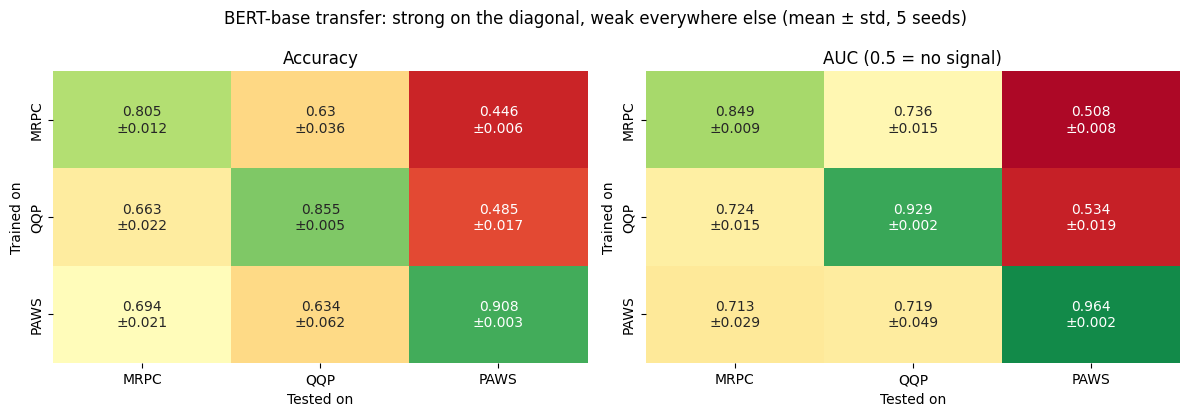

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, m, title, lo in [(ax[0], "acc", "Accuracy", 0.4), (ax[1], "auc", "AUC (0.5 = no signal)", 0.5)]:
    mean = xfer.pivot_table(index="train", columns="test", values=m).loc[order, order]
    std = xfer.pivot_table(index="train", columns="test", values=m, aggfunc=lambda x: x.std(ddof=1)).loc[order, order]
    annot = mean.round(3).astype(str) + "\n±" + std.round(3).astype(str)
    sns.heatmap(mean, annot=annot, fmt="", cmap="RdYlGn", vmin=lo, vmax=1, cbar=False, ax=a,
                xticklabels=[o.upper() for o in order], yticklabels=[o.upper() for o in order])
    a.set_title(title); a.set_xlabel("Tested on"); a.set_ylabel("Trained on")
plt.suptitle("BERT-base transfer: strong on the diagonal, weak everywhere else (mean ± std, 5 seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/1_transfer_heatmaps.png", dpi=200); plt.show()

### Histograms of predicted P(paraphrase) on PAWS. Score Distributions on PAWS

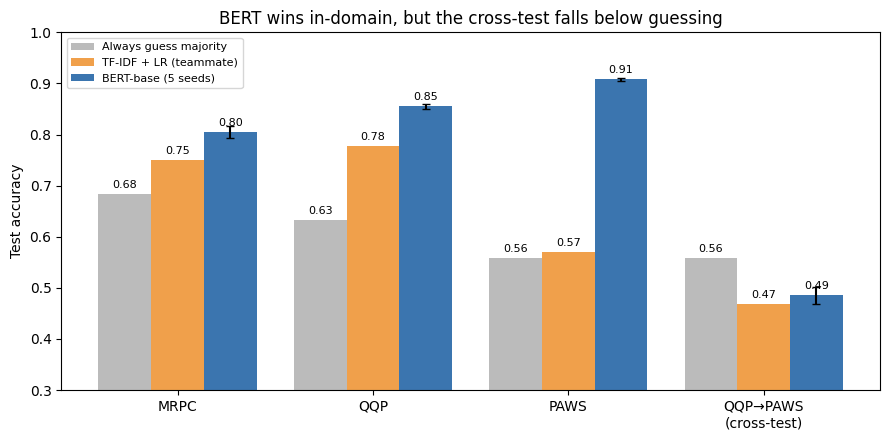

In [28]:
def g(tr, te):
    v = xfer[(xfer.train == tr) & (xfer.test == te)].acc
    return v.mean(), v.std(ddof=1)

pairs = [("mrpc", "mrpc"), ("qqp", "qqp"), ("paws", "paws"), ("qqp", "paws")]
labels = ["MRPC", "QQP", "PAWS", "QQP→PAWS\n(cross-test)"]
bert = [g(*p) for p in pairs]
base = [0.750, 0.778, 0.570, 0.469]        # her results_baseline.csv
maj  = [0.684, 0.633, 0.558, 0.558]

x = np.arange(4); w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, maj, w, label="Always guess majority", color="#bbbbbb")
ax.bar(x, base, w, label="TF-IDF + LR (teammate)", color="#f0a04b")
ax.bar(x + w, [b[0] for b in bert], w, yerr=[b[1] for b in bert], capsize=3, label="BERT-base (5 seeds)", color="#3b75af")
for xs, vals in [(x - w, maj), (x, base), (x + w, [b[0] for b in bert])]:
    for xi, v in zip(xs, vals): ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0.3, 1.0); ax.set_ylabel("Test accuracy")
ax.set_title("BERT wins in-domain, but the cross-test falls below guessing")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout()
plt.savefig(f"{FIG}/2_bert_vs_baseline.png", dpi=200); plt.show()

### Accuracy or fraction predicted “paraphrase” against word overlap. PAWS Accuracy by Word Overlap

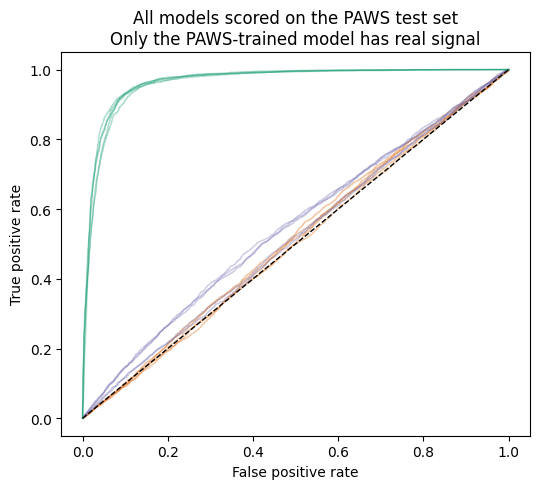

In [31]:
colors = {"mrpc": "#d95f02", "qqp": "#7570b3", "paws": "#1b9e77"}
fig, ax = plt.subplots(figsize=(5.5, 5))
for tr in order:
    aucs = []
    for s in SEEDS:
        lg = np.load(f"{OUT}/xfer_{tr}_on_paws_s{s}_logits.npy")
        pr = softmax(lg, axis=-1)[:, 1]
        fpr, tpr, _ = roc_curve(y_paws, pr)
        aucs.append(xfer[(xfer.train == tr) & (xfer.test == "paws") & (xfer.seed == s)].auc.iloc[0])
        ax.plot(fpr, tpr, color=colors[tr], alpha=0.35, lw=1)
    ax.plot([], [], color=colors[tr], lw=2, label=f"Model trained on {tr.upper()} (AUC {np.mean(aucs):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Coin flip")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("All models scored on the PAWS test set\nOnly the PAWS-trained model has real signal")
plt.tight_layout(); plt.savefig(f"{FIG}/3_roc_on_paws.png", dpi=200); plt.show()

### PAWS Confusion Matrices by Training Dataset

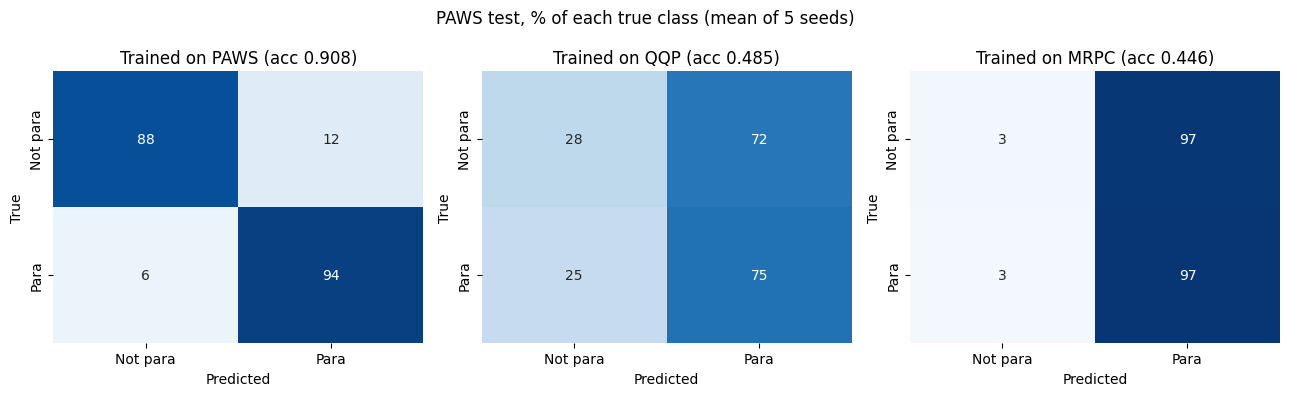

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, tr in zip(ax, ["paws", "qqp", "mrpc"]):
    cms = np.mean([confusion_matrix(y_paws, np.load(f"{OUT}/xfer_{tr}_on_paws_s{s}_preds.npy"), normalize="true")
                   for s in SEEDS], axis=0) * 100
    acc = xfer[(xfer.train == tr) & (xfer.test == "paws")].acc.mean()
    sns.heatmap(cms, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=a,
                xticklabels=["Not para", "Para"], yticklabels=["Not para", "Para"])
    a.set_title(f"Trained on {tr.upper()} (acc {acc:.3f})"); a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.suptitle("PAWS test, % of each true class (mean of 5 seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/4_confusion_paws.png", dpi=200); plt.show()

#### Preparing and Exporting files to push to git

In [9]:
import os, numpy as np, pandas as pd

SEEDS = [42, 43, 44, 45, 46]
SPLITS = "/home/bhandari.ru/NLP project/splits"
OUT = "/scratch/bhandari.ru/paraphrase/out_team"
RESULTS = "/home/bhandari.ru/NLP project/bert_base_results"
FIG = f"{RESULTS}/figures"
order = ["mrpc", "qqp", "paws"]

data = {ds: {sp: pd.read_csv(f"{SPLITS}/{ds}_{sp}.csv", keep_default_na=False)
             for sp in ["train", "dev", "test"]} for ds in order}

# use scratch if the logits are still there, otherwise the home backup
SRC = OUT if os.path.exists(f"{OUT}/xfer_qqp_on_paws_s42_logits.npy") else RESULTS
print("reading logits from:", SRC)

reading logits from: /scratch/bhandari.ru/paraphrase/out_team


In [10]:
from scipy.special import softmax
EXPORT = "/home/bhandari.ru/NLP project/export"
os.makedirs(f"{EXPORT}/preds", exist_ok=True); os.makedirs(f"{EXPORT}/figures", exist_ok=True)

for tr in order:
    for te in order:
        df = data[te]["test"][["sentence1", "sentence2", "label"]].copy()
        probs = np.stack([softmax(np.load(f"{SRC}/xfer_{tr}_on_{te}_s{s}_logits.npy"), axis=-1)[:, 1]
                          for s in SEEDS])
        assert probs.shape[1] == len(df)
        df["prob"] = probs.mean(0).round(4)
        df["pred"] = (df["prob"] > 0.5).astype(int)
        for s, p in zip(SEEDS, probs):
            df[f"pred_s{s}"] = (p > 0.5).astype(int)
        df = df[["sentence1", "sentence2", "label", "pred", "prob"] + [f"pred_s{s}" for s in SEEDS]]
        df.to_csv(f"{EXPORT}/preds/bert_{tr}_to_{te}.csv", index=False)

!cp "{FIG}"/*.png "{EXPORT}/figures/"
!cp "{RESULTS}/bert_summary.csv" "{RESULTS}/transfer_all_runs.csv" "{EXPORT}/"

In [12]:
   !cd "/home/bhandari.ru/NLP project" && zip -r export.zip export

  adding: export/ (stored 0%)
  adding: export/.ipynb_checkpoints/ (stored 0%)
  adding: export/.ipynb_checkpoints/bert_summary-checkpoint.csv (deflated 43%)
  adding: export/bert_summary.csv (deflated 43%)
  adding: export/figures/ (stored 0%)
  adding: export/figures/1_transfer_heatmaps.png (deflated 10%)
  adding: export/figures/2_bert_vs_baseline.png (deflated 20%)
  adding: export/figures/3_roc_on_paws.png (deflated 5%)
  adding: export/figures/4_confusion_paws.png (deflated 18%)
  adding: export/preds/ (stored 0%)
  adding: export/preds/bert_mrpc_to_mrpc.csv (deflated 67%)
  adding: export/preds/bert_mrpc_to_paws.csv (deflated 72%)
  adding: export/preds/bert_mrpc_to_qqp.csv (deflated 65%)
  adding: export/preds/bert_paws_to_mrpc.csv (deflated 67%)
  adding: export/preds/bert_paws_to_paws.csv (deflated 72%)
  adding: export/preds/bert_paws_to_qqp.csv (deflated 65%)
  adding: export/preds/bert_qqp_to_mrpc.csv (deflated 67%)
  adding: export/preds/bert_qqp_to_paws.csv (deflated 71%